# Six news-category formulas: trading comparison

Approved candidates: original 40/20/20/20, equal weights, Bitcoin only, crypto only, Bitcoin 80% with the other three each 20%/3, and crypto 80% with the other three each 20%/3. Weights describe the four news categories, not the final P-score. The final P-score remains **70% news and 30% technical**.

Use only the original **192 September 24-October 31 observations**, with their matching Azure category scores. Select each formula's threshold independently on the first **134 observations** and freeze it for the remaining **58**. The forty newer observations remain excluded. The later58 have already been inspected in previous studies, so this is an exploratory comparison, not an independent validation.

Common rules: 24-hour hold; threshold grid0.05 to0.55 in0.05 steps; at least10 completed earlier trades; select maximum earlier net return, breaking ties by more trades then smaller threshold. If no threshold qualifies, report no eligible setting and do not invent a later result. Buying-only and long/short are separate. Each period starts with $1,000, with0.10% fee and0.05% slippage on each side. One position at a time, full available capital, next hourly open strictly after the signal; trades crossing the period endpoint are excluded. No leverage, funding, borrowing, margin, liquidation or stop-loss/take-profit model.


In [1]:
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
%matplotlib inline
candidates=[Path.cwd(),Path.cwd()/"notebooks/category_research"]
HERE=next(p for p in candidates if (p/"audit_results/azure_matching_previous_192.csv").exists())
PROJECT=HERE.parents[1]
OUT=HERE/"category_weight_results"
OUT.mkdir(exist_ok=True)
INPUTS=[HERE/"audit_results/azure_matching_previous_192.csv",PROJECT/"notebooks/recent_data/btc_hourly_recent.csv",
        PROJECT/"notebooks/recent_data/signals_recent.csv",PROJECT/"notebooks/results_recent/recent_weight_training_threshold_selections.csv",
        PROJECT/"notebooks/results_recent/recent_weight_selected_segment_results.csv"]
EXPECTED={'azure_matching_previous_192.csv': 'f5fc7adaf15528c7bac8bb2c5a76be729cf55930e299f00772dd8584ed83500e', 'btc_hourly_recent.csv': '8b362387fe685c09c2da4149547f867b5eb3a905452a88cbafad65a210b53551', 'signals_recent.csv': 'b3a15d9f7375e01f24b5f1b18db8109c80102db425b47264925cead502db2e17', 'recent_weight_training_threshold_selections.csv': 'b19faa4660cf427782dd07e0e8bb5fe4d2a328fa98116c011ab091f6f488683f', 'recent_weight_selected_segment_results.csv': 'e5730367b8025167fb15100225c71a27090f4096e4cf553c3245cc16b23c892d'}
for p in INPUTS:
    assert hashlib.sha256(p.read_bytes()).hexdigest()==EXPECTED[p.name]
signals=pd.read_csv(INPUTS[0])
old=pd.read_csv(INPUTS[2])
for frame in [signals,old]:
    frame["timestamp"]=pd.to_datetime(frame.timestamp,format="mixed",utc=True)
    frame.sort_values("timestamp",inplace=True)
    frame.reset_index(drop=True,inplace=True)
assert len(signals)==len(old)==192
assert signals.timestamp.dt.floor("ms").equals(old.timestamp)
assert signals.symbol.equals(old.symbol)
market=pd.read_csv(INPUTS[1])
market["open_time"]=pd.to_datetime(market.open_time,utc=True)
P=market.set_index("open_time").open
assert P.index.is_unique and P.index.is_monotonic_increasing
assert P.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
signals["entry_time"]=signals.timestamp.dt.floor("h")+pd.Timedelta(hours=1)
assert signals.entry_time.gt(signals.timestamp).all()
CATEGORY_COLUMNS=["bitcoin_score","crypto_score","politics_score","war_macro_score"]
assert np.isfinite(signals[CATEGORY_COLUMNS+["ta_score"]].to_numpy()).all()
FORMULAS={
    "Original":(.4,.2,.2,.2),
    "Equal":(.25,.25,.25,.25),
    "Bitcoin only":(1.,0.,0.,0.),
    "Crypto only":(0.,1.,0.,0.),
    "Bitcoin 80%":(.8,.2/3,.2/3,.2/3),
    "Crypto 80%":(.2/3,.8,.2/3,.2/3),
}
formula_rows=[]
SCORE_COLUMNS={}
for i,(name,weights) in enumerate(FORMULAS.items()):
    assert np.isclose(sum(weights),1,atol=1e-15,rtol=0)
    news_col=f"category_news_{i}"
    p_col=f"category_p_{i}"
    # Use scalar Python round, matching the production formula's convention.
    signals[news_col]=signals.apply(lambda r:round(sum(float(r[c])*w for c,w in zip(CATEGORY_COLUMNS,weights)),4),axis=1)
    signals[p_col]=signals.apply(lambda r:max(-1.,min(1.,round(float(r[news_col])*.7+float(r.ta_score)*.3,4))),axis=1)
    SCORE_COLUMNS[name]=p_col
    formula_rows.append(dict(formula=name,score_column=p_col,**dict(zip(CATEGORY_COLUMNS,weights))))
formulas=pd.DataFrame(formula_rows)
assert np.allclose(signals.category_news_0,signals.news_score,atol=1e-10,rtol=0)
assert np.allclose(signals.category_p_0,signals.p_score,atol=1e-10,rtol=0)
formulas.to_csv(OUT/"candidate_formulas.csv",index=False)
signals.to_csv(OUT/"original192_candidate_scores.csv",index=False)
display(formulas)
plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False})


,formula,score_column,bitcoin_score,crypto_score,politics_score,war_macro_score
0,Original,category_p_0,0.400000,0.200000,0.200000,0.200000
1,Equal,category_p_1,0.250000,0.250000,0.250000,0.250000
2,Bitcoin only,category_p_2,1.000000,0.000000,0.000000,0.000000
3,Crypto only,category_p_3,0.000000,1.000000,0.000000,0.000000
4,Bitcoin 80%,category_p_4,0.800000,0.066667,0.066667,0.066667
5,Crypto 80%,category_p_5,0.066667,0.800000,0.066667,0.066667


## Shared simulation engine

The following engine is copied from the previous executed research. It includes entry/exit slippage, fees, cash between trades and drawdown measured at hourly open marks. The long/short model is hypothetical and unleveraged; its short-side accounting excludes the practical cost and availability of borrowing. Hourly marks do not capture intrahour drawdowns. The ledger's `signal_score` is the candidate composite used to trade; `p_score` retains the original score for reference.


In [2]:
THRESHOLD_GRID=[round(x,2) for x in np.arange(.05,.551,.05)]
HOLD_GRID=[1,4,8,12,24,48]
MODES=["Buying only","Long and short"]
STARTING_EQUITY=1000.
FEE_RATE=.001
SLIPPAGE_RATE=.0005
MIN_TRAINING_TRADES=10
RECENT_N=len(signals)
RECENT_CUT=int(RECENT_N*.7)
RECENT_SPLIT=signals.timestamp.iloc[RECENT_CUT]
RECENT_END=P.index.max()
SEGMENTS=[("Earlier",0,RECENT_CUT),("Later",RECENT_CUT,RECENT_N),("Full recent sample",0,RECENT_N)]
PRICE_LOOKUP=P.to_dict()
SIMULATIONS={}
TRADE_COLS=["source_row","signal_time","entry_time","exit_time","side","p_score","entry_open","exit_open",
            "entry_fill","exit_fill","quantity","initial_equity","ending_equity","net_pnl","net_return","fees","signal_score","score_column"]

def simulate_recent_score(score_column,threshold,holding_hours,mode,begin,end):
    key=(score_column,threshold,holding_hours,mode,begin,end)
    if key in SIMULATIONS:
        return SIMULATIONS[key]
    start=signals.entry_time.iloc[begin]
    finish=RECENT_END if end==RECENT_N else signals.timestamp.iloc[end].floor("h")
    capital=STARTING_EQUITY
    next_free=start
    trades=[]
    curve=pd.Series(np.nan,index=P.loc[start:finish].index,dtype=float)
    curve.iloc[0]=capital
    for i in range(begin,end):
        row=signals.iloc[i]
        signal_score=float(row[score_column])
        side=1 if signal_score>=threshold else (-1 if mode=="Long and short" and signal_score<=-threshold else 0)
        if not side:
            continue
        entry=row.entry_time
        exit_time=entry+pd.Timedelta(hours=holding_hours)
        if entry<start or entry<next_free or exit_time>finish or entry not in PRICE_LOOKUP or exit_time not in PRICE_LOOKUP:
            continue
        entry_mid=float(PRICE_LOOKUP[entry]);exit_mid=float(PRICE_LOOKUP[exit_time])
        entry_fill=entry_mid*(1+side*SLIPPAGE_RATE)
        exit_fill=exit_mid*(1-side*SLIPPAGE_RATE)
        quantity=capital/(entry_fill*(1+FEE_RATE))
        fee_in=quantity*entry_fill*FEE_RATE
        fee_out=quantity*exit_fill*FEE_RATE
        final=capital-fee_in+side*quantity*(exit_fill-entry_fill)-fee_out
        assert final>0,"Equity exhausted; liquidation is not implemented in this model."
        marks=P.loc[entry:exit_time].iloc[:-1]
        curve.loc[marks.index]=capital-fee_in+side*quantity*(marks-entry_fill)
        curve.loc[exit_time]=final
        trades.append(dict(source_row=i,signal_time=row.timestamp,entry_time=entry,exit_time=exit_time,
            side=side,p_score=row.p_score,signal_score=signal_score,score_column=score_column,entry_open=entry_mid,exit_open=exit_mid,entry_fill=entry_fill,
            exit_fill=exit_fill,quantity=quantity,initial_equity=capital,ending_equity=final,
            net_pnl=final-capital,net_return=final/capital-1,fees=fee_in+fee_out))
        capital=final
        next_free=exit_time
    curve=curve.ffill()
    values=np.r_[STARTING_EQUITY,curve.to_numpy()]
    max_dd=float(np.min(values/np.maximum.accumulate(values)-1)*100)
    table=pd.DataFrame(trades,columns=TRADE_COLS)
    gross_profit=sum(max(t["net_pnl"],0) for t in trades)
    gross_loss=-sum(min(t["net_pnl"],0) for t in trades)
    metrics=dict(score_column=score_column,mode=mode,threshold=threshold,holding_hours=holding_hours,trades=len(table),
        longs=sum(t["side"]==1 for t in trades),shorts=sum(t["side"]==-1 for t in trades),
        return_pct=(capital/STARTING_EQUITY-1)*100,final_equity=capital,hourly_max_drawdown_pct=max_dd,
        win_rate_pct=sum(t["net_pnl"]>0 for t in trades)/len(trades)*100 if trades else np.nan,
        profit_factor=gross_profit/gross_loss if gross_loss else np.nan,
        total_fees=sum(t["fees"] for t in trades),start_time=str(start),end_time=str(finish))
    run={"metrics":metrics,"trades":table,"equity":curve}
    SIMULATIONS[key]=run
    return run

def simulate_recent_p(threshold,holding_hours,mode,begin,end):
    return simulate_recent_score("p_score",threshold,holding_hours,mode,begin,end)


assert RECENT_CUT==134 and RECENT_N==192
HOLDING_HOURS=24
print("Earlier rows: 0-133; later rows:134-191")
print("Split score timestamp:",RECENT_SPLIT)
print("Earlier final eligible hourly open:",RECENT_SPLIT.floor("h"))
print("Last frozen hourly open:",RECENT_END)


Earlier rows: 0-133; later rows:134-191
Split score timestamp: 2026-10-22 02:48:32.320481+00:00
Earlier final eligible hourly open: 2026-10-22 02:00:00+00:00
Last frozen hourly open: 2026-10-31 14:00:00+00:00


## Select thresholds using earlier observations only

All candidate/threshold results in this grid use earlier observations. Thresholds and earlier eligibility are fixed before the next cell evaluates the later period. Selecting a least-bad earlier return when all eligible returns are negative does not imply the setting is profitable.


In [3]:
grid_rows=[]
for name,column in SCORE_COLUMNS.items():
    for mode in MODES:
        for threshold in THRESHOLD_GRID:
            run=simulate_recent_score(column,threshold,HOLDING_HOURS,mode,0,RECENT_CUT)
            grid_rows.append(dict(formula=name,**run["metrics"]))
grid=pd.DataFrame(grid_rows)
assert len(grid)==6*2*11
choices=[]
for name,column in SCORE_COLUMNS.items():
    for mode in MODES:
        eligible=grid.loc[grid.formula.eq(name)&grid["mode"].eq(mode)&grid.trades.ge(MIN_TRAINING_TRADES)]
        if eligible.empty:
            choices.append(dict(formula=name,mode=mode,status="No eligible earlier setting",threshold=np.nan,earlier_return_pct=np.nan,earlier_trades=np.nan))
            continue
        best=eligible.sort_values(["return_pct","trades","threshold"],ascending=[False,False,True],kind="stable").iloc[0]
        choices.append(dict(formula=name,mode=mode,status="Eligible",threshold=float(best.threshold),
                            earlier_return_pct=float(best.return_pct),earlier_trades=int(best.trades)))
choices=pd.DataFrame(choices)
grid.to_csv(OUT/"earlier_threshold_grid.csv",index=False)
choices.to_csv(OUT/"earlier_selected_thresholds.csv",index=False)
display(choices.round(4))


,formula,mode,status,threshold,earlier_return_pct,earlier_trades
0,Original,Buying only,Eligible,0.05,-4.4835,11
1,Original,Long and short,Eligible,0.25,1.3572,10
2,Equal,Buying only,Eligible,0.05,-6.4201,10
3,Equal,Long and short,Eligible,0.20,-0.0325,10
4,Bitcoin only,Buying only,Eligible,0.35,1.3085,11
5,Bitcoin only,Long and short,Eligible,0.35,1.7585,14
6,Crypto only,Buying only,Eligible,0.05,-5.4615,14
7,Crypto only,Long and short,Eligible,0.30,-5.1626,11
8,Bitcoin 80%,Buying only,Eligible,0.25,1.3085,11
9,Bitcoin 80%,Long and short,Eligible,0.30,-0.3581,14


## Evaluate frozen settings on the later58 observations

Each period restarts at $1,000. Positions cannot cross the split and no future signal is used for an earlier trade. Later returns do not influence threshold selection. Ineligible candidates remain unavailable rather than becoming a zero-return strategy.


In [4]:
selected_rows=[]
for choice in choices.itertuples():
    if choice.status!="Eligible":
        continue
    column=SCORE_COLUMNS[choice.formula]
    for segment,begin,end in [("Earlier",0,RECENT_CUT),("Later",RECENT_CUT,RECENT_N)]:
        run=simulate_recent_score(column,choice.threshold,HOLDING_HOURS,choice.mode,begin,end)
        selected_rows.append(dict(formula=choice.formula,segment=segment,**run["metrics"]))
        tag=f"{list(FORMULAS).index(choice.formula)}_"+choice.mode.lower().replace(" ","_")+"_"+segment.lower()
        run["trades"].to_csv(OUT/(tag+"_trades.csv"),index=False)
        run["equity"].rename("equity").rename_axis("timestamp").to_csv(OUT/(tag+"_equity.csv"))
selected=pd.DataFrame(selected_rows)
summary=choices.copy()
later=selected.loc[selected.segment.eq("Later"),["formula","mode","return_pct","trades","hourly_max_drawdown_pct","win_rate_pct","final_equity"]]
later=later.rename(columns={"return_pct":"later_return_pct","trades":"later_trades","hourly_max_drawdown_pct":"later_drawdown_pct","win_rate_pct":"later_win_rate_pct","final_equity":"later_final_equity"})
summary=summary.merge(later,on=["formula","mode"],how="left",validate="one_to_one")
selected.to_csv(OUT/"selected_segment_results.csv",index=False)
summary.to_csv(OUT/"six_formula_comparison.csv",index=False)
for mode in MODES:
    display(Markdown("### "+mode))
    display(summary.loc[summary["mode"].eq(mode),["formula","status","threshold","earlier_return_pct","earlier_trades",
                    "later_return_pct","later_trades","later_drawdown_pct"]].round(3))


### Buying only

,formula,status,threshold,earlier_return_pct,earlier_trades,later_return_pct,later_trades,later_drawdown_pct
0,Original,Eligible,0.05,-4.484,11,-2.947,3,-3.261
2,Equal,Eligible,0.05,-6.420,10,-2.947,3,-3.261
4,Bitcoin only,Eligible,0.35,1.308,11,-1.433,1,-2.203
6,Crypto only,Eligible,0.05,-5.461,14,-2.772,4,-3.261
8,Bitcoin 80%,Eligible,0.25,1.308,11,-1.433,1,-2.203
10,Crypto 80%,Eligible,0.05,-5.461,14,-2.947,3,-3.261


### Long and short

,formula,status,threshold,earlier_return_pct,earlier_trades,later_return_pct,later_trades,later_drawdown_pct
1,Original,Eligible,0.25,1.357,10,4.569,5,-2.471
3,Equal,Eligible,0.20,-0.033,10,4.569,5,-2.471
5,Bitcoin only,Eligible,0.35,1.759,14,-1.211,5,-2.984
7,Crypto only,Eligible,0.30,-5.163,11,6.618,5,-2.124
9,Bitcoin 80%,Eligible,0.30,-0.358,14,-1.211,5,-2.984
11,Crypto 80%,Eligible,0.25,-6.689,12,4.483,6,-2.285


## Reconciliation and accounting checks

The original candidate must reproduce the previous fixed24-hour 70/30 results. Independently verify earlier-only selection, selected trade timing, no overlaps, 24-hour exits, costs, compounding and starting equity. No other holding periods or newer observations are evaluated.


In [5]:
previous_choices=pd.read_csv(INPUTS[3])
previous_results=pd.read_csv(INPUTS[4])
for mode in MODES:
    current=choices.loc[choices.formula.eq("Original")&choices["mode"].eq(mode)].iloc[0]
    reference=previous_choices.loc[previous_choices.news_pct.eq(70)&previous_choices["mode"].eq(mode)].iloc[0]
    assert current.threshold==reference.threshold
    assert np.isclose(current.earlier_return_pct,reference.earlier_return_pct,atol=1e-10,rtol=0)
    for segment in ["Earlier","Later"]:
        a=selected.loc[selected.formula.eq("Original")&selected["mode"].eq(mode)&selected.segment.eq(segment)].iloc[0]
        b=previous_results.loc[previous_results.news_pct.eq(70)&previous_results["mode"].eq(mode)&previous_results.segment.eq(segment)].iloc[0]
        for field in ["trades","return_pct","hourly_max_drawdown_pct","final_equity"]:
            assert np.isclose(a[field],b[field],atol=1e-9,rtol=0),(mode,segment,field)
for choice in choices.itertuples():
    eligible=grid.loc[grid.formula.eq(choice.formula)&grid["mode"].eq(choice.mode)&grid.trades.ge(10)]
    if choice.status!="Eligible":
        assert eligible.empty
        continue
    assert np.isclose(choice.earlier_return_pct,eligible.return_pct.max(),atol=1e-12,rtol=0)
    for segment,begin,end in [("Earlier",0,134),("Later",134,192)]:
        run=simulate_recent_score(SCORE_COLUMNS[choice.formula],choice.threshold,24,choice.mode,begin,end)
        ledger=run["trades"]
        capital=1000.
        last_exit=None
        finish=RECENT_END if end==192 else RECENT_SPLIT.floor("h")
        for trade in ledger.itertuples():
            assert begin<=trade.source_row<end
            assert trade.entry_time>trade.signal_time
            assert trade.exit_time-trade.entry_time==pd.Timedelta(hours=24)
            assert trade.exit_time<=finish
            assert last_exit is None or trade.entry_time>=last_exit
            assert abs(trade.signal_score)>=choice.threshold
            assert trade.side==(1 if trade.signal_score>=choice.threshold else -1)
            if choice.mode=="Buying only": assert trade.side==1
            entry_fill=float(P.loc[trade.entry_time])*(1+trade.side*.0005)
            exit_fill=float(P.loc[trade.exit_time])*(1-trade.side*.0005)
            quantity=capital/(entry_fill*1.001)
            fees=quantity*(entry_fill+exit_fill)*.001
            capital=capital+trade.side*quantity*(exit_fill-entry_fill)-fees
            assert np.isclose(capital,trade.ending_equity,rtol=0,atol=1e-9)
            last_exit=trade.exit_time
        assert np.isclose(capital,run["metrics"]["final_equity"],rtol=0,atol=1e-9)
        curve=run["equity"].to_numpy()
        v=np.r_[1000.,curve]
        independent_dd=(v/np.maximum.accumulate(v)-1).min()*100
        assert np.isclose(independent_dd,run["metrics"]["hourly_max_drawdown_pct"],rtol=0,atol=1e-10)
for name_a,name_b in [("Original","Equal"),("Bitcoin only","Bitcoin 80%")]:
    ledgers=[]
    for name in [name_a,name_b]:
        choice=choices.loc[choices.formula.eq(name)&choices["mode"].eq("Long and short")].iloc[0]
        run=simulate_recent_score(SCORE_COLUMNS[name],float(choice.threshold),24,"Long and short",134,192)
        ledgers.append(run["trades"][["entry_time","exit_time","side"]])
    assert ledgers[0].equals(ledgers[1])
checks=pd.DataFrame({"check":["Original formulas reproduce stored scores","Earlier-only threshold selection verified",
       "Original fixed24h study reproduced in both modes/periods","Selected trade timing, eligibility and no overlaps verified",
       "Independent selected-trade costs and equity reconciliation","Hourly drawdowns and starting1000 verified"],"passed":True})
display(checks)
checks.to_csv(OUT/"comparison_checks.csv",index=False)


,check,passed
0,Original formulas reproduce stored scores,True
1,Earlier-only threshold selection verified,True
2,Original fixed24h study reproduced in both mod...,True
3,"Selected trade timing, eligibility and no over...",True
4,Independent selected-trade costs and equity re...,True
5,Hourly drawdowns and starting1000 verified,True


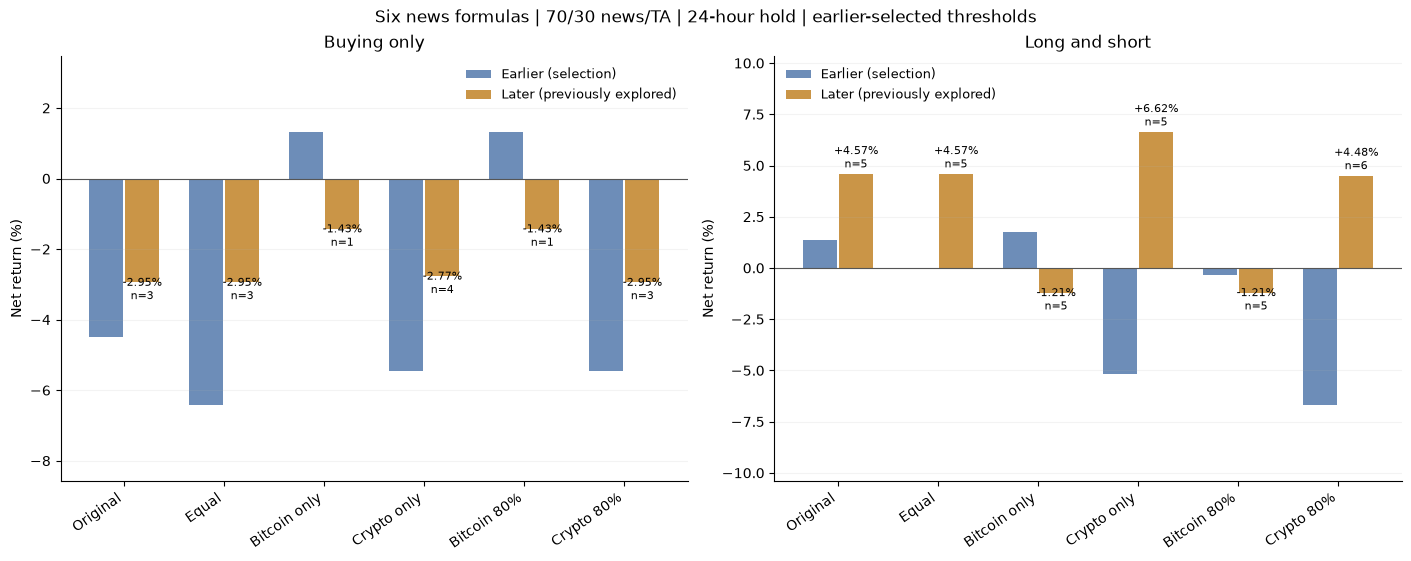

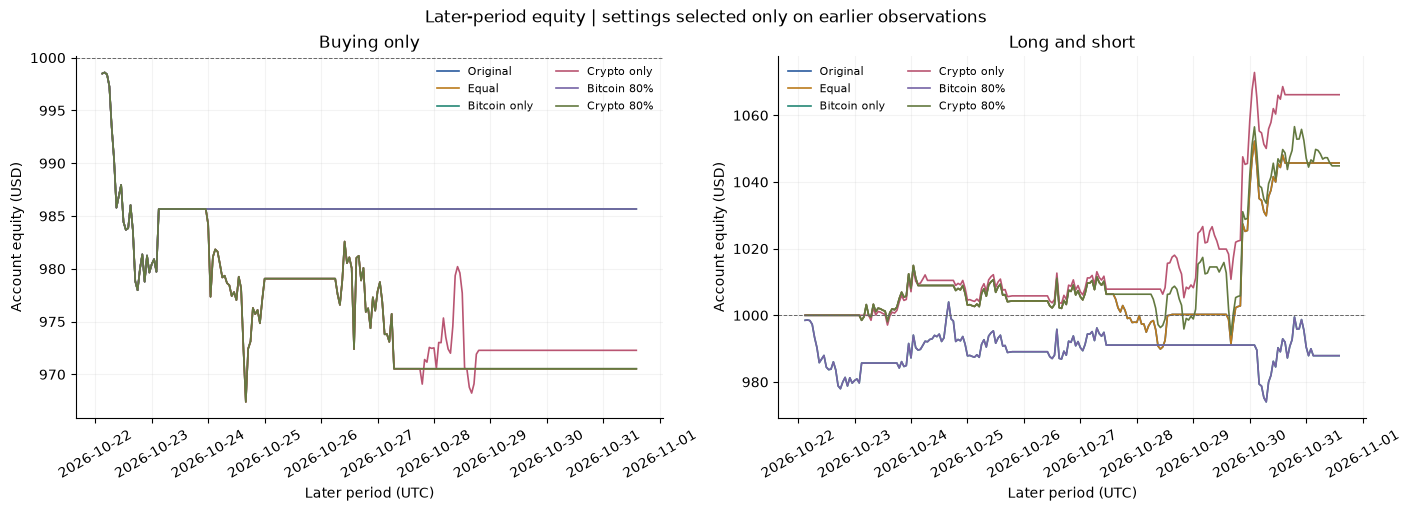

In [6]:
fig,axes=plt.subplots(1,2,figsize=(14,5.5),layout="constrained")
names=list(FORMULAS)
x=np.arange(len(names))
for ax,mode in zip(axes,MODES):
    part=summary.loc[summary["mode"].eq(mode)].set_index("formula").reindex(names)
    ax.bar(x-.18,part.earlier_return_pct,.34,label="Earlier (selection)",color="#6d8db8")
    ax.bar(x+.18,part.later_return_pct,.34,label="Later (previously explored)",color="#ca9547")
    for j,row in enumerate(part.itertuples()):
        if row.status!="Eligible":
            ax.text(j,0,"Ineligible",rotation=90,ha="center",va="bottom")
        else:
            offset=5 if row.later_return_pct>=0 else -12
            ax.annotate(f"{row.later_return_pct:+.2f}%\nn={int(row.later_trades)}",(j+.18,row.later_return_pct),
                        xytext=(0,offset),textcoords="offset points",ha="center",fontsize=8)
    ax.axhline(0,color="#555555",lw=.8)
    ax.set_xticks(x,names,rotation=35,ha="right")
    ax.set(title=mode,ylabel="Net return (%)")
    ax.margins(y=.28)
    ax.legend(frameon=False,fontsize=9)
    ax.grid(axis="y",alpha=.15)
fig.suptitle("Six news formulas | 70/30 news/TA | 24-hour hold | earlier-selected thresholds")
fig.savefig(OUT/"six_formula_returns.png",dpi=150,bbox_inches="tight",facecolor="white")
display(fig);plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(14,5),layout="constrained")
colors=["#2a5b9e","#bb7b1c","#258775","#b95572","#7664a5","#637940"]
for ax,mode in zip(axes,MODES):
    for (name,column),color in zip(SCORE_COLUMNS.items(),colors):
        choice=choices.loc[choices.formula.eq(name)&choices["mode"].eq(mode)].iloc[0]
        if choice.status!="Eligible":continue
        equity=simulate_recent_score(column,float(choice.threshold),24,mode,134,192)["equity"]
        ax.plot(equity.index,equity,label=name,color=color,lw=1.2)
    ax.axhline(1000,color="#666666",lw=.7,ls="--")
    ax.set(title=mode,ylabel="Account equity (USD)",xlabel="Later period (UTC)")
    ax.legend(frameon=False,fontsize=8,ncol=2)
    ax.tick_params(axis="x",rotation=30)
    ax.grid(alpha=.15)
fig.suptitle("Later-period equity | settings selected only on earlier observations")
fig.savefig(OUT/"six_formula_later_equity.png",dpi=150,bbox_inches="tight",facecolor="white")
display(fig);plt.close(fig)


## Interpretation and approval boundary

Later returns compare fixed earlier-selected settings. A higher later result here must not be reinterpreted as an earlier prediction or used as proof of the best formula. Repeated exploration of these58 observations and small trade counts limit the conclusion. No additional formula candidates, folds, holding periods, stress tests or newer-sample performance have been evaluated.


In [7]:
report={"approved_scope":"Six category formulas;fixed70/30 news/TA;24h;earlier134-selected thresholds;later58 comparison",
        "newer40_evaluated":False,"input_sha256":EXPECTED,
        "formulas":formulas.to_dict("records"),"comparison":json.loads(summary.to_json(orient="records")),
        "assumptions":{"starting_equity":1000,"fee_each_side":.001,"slippage_each_side":.0005,
                       "threshold_grid":THRESHOLD_GRID,"min_earlier_trades":10,"holding_hours":24},
        "limitation":"Later58 already explored;small trade counts;short borrowing/funding/liquidation excluded"}
(OUT/"six_formula_results.json").write_text(json.dumps(report,indent=2),encoding="utf-8")


7058

## Findings

For long/short, the original formula returned +1.36% earlier and +4.57% later (five later trades). Equal weights returned -0.03% earlier and +4.57% later; its selected threshold led to exactly the same later entries and directions as the original formula.

Bitcoin only was the strongest earlier long/short candidate at +1.76%, but returned -1.21% later (five trades). Bitcoin80% returned -0.36% earlier and -1.21% later, with the same later trades as Bitcoin only. Crypto only returned -5.16% earlier and +6.62% later (five trades). Crypto80% returned -6.69% earlier and +4.48% later (six trades).

All six buying-only candidates lost later, with only one to four completed later trades. The sample does not establish a reliable improvement over the original weights. Choosing crypto only because it has the highest later return would use hindsight, while choosing the strongest earlier candidate would have selected Bitcoin only, which lost later. These results do not establish the best weights for future trading.

The forty newer observations remain excluded. No further study or publication has been performed.
